
# Equity Market Analytics — Python Analysis

## Project Objective

Analyze historical stock market data using Python to understand:
- Stock price performance
- Daily and cumulative returns
- Annualized volatility
- Maximum drawdown
- Relationships between stocks
- Portfolio performance and risk


In [1]:
print("Hello, my Equity Market Analytics project!")

Hello, my Equity Market Analytics project!


# Equity Market Analytics — Python Project

## 1. Project Objective

The objective of this project is to analyze historical stock market data using Python, SQL, and Power BI.

## 2. What I Will Analyze

- Historical stock prices
- Daily stock returns
- Cumulative returns
- Annual stock performance
- Investment risk and volatility
- Maximum drawdown
- Relationships between stocks
- Portfolio performance

## 3. Tools

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- MySQL
- Power BI



In [3]:
# CONNECT PYTHON TO YOUR DATASET.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Install the MYSQL Connector.

%pip install mysql-connector-python

Defaulting to user installation because normal site-packages is not writeable
                                              0.0/17.7 MB ? eta -:--:--
                                              0.2/17.7 MB 5.6 MB/s eta 0:00:04
                                              0.4/17.7 MB 4.6 MB/s eta 0:00:04
     -                                        0.5/17.7 MB 4.2 MB/s eta 0:00:05
     -                                        0.7/17.7 MB 4.1 MB/s eta 0:00:05
     --                                       0.9/17.7 MB 3.9 MB/s eta 0:00:05
     --                                       1.1/17.7 MB 4.0 MB/s eta 0:00:05
     --                                       1.3/17.7 MB 3.9 MB/s eta 0:00:05
     ---                                      1.4/17.7 MB 3.7 MB/s eta 0:00:05
     ---                                      1.6/17.7 MB 3.7 MB/s eta 0:00:05
     ---                                      1.7/17.7 MB 3.6 MB/s eta 0:00:05
     ----                                     1.8/17.7 MB 3.


[notice] A new release of pip is available: 23.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
# Import the MYSQL Connector.

import mysql.connector

print("MySQL connector imported successfully!")

MySQL connector imported successfully!


In [3]:
# Connect Python to your MYSQL Database.

import mysql.connector
from getpass import getpass

mysql_user = input("Enter your MySQL username: ")
mysql_password = getpass("Enter your MySQL password: ")

connection = mysql.connector.connect(
    host="localhost",
    user=mysql_user,
    password=mysql_password,
    database="equity_market_analytics"
)

print("Successfully connected to MySQL!")

Enter your MySQL username:  root
Enter your MySQL password:  ········


Successfully connected to MySQL!


In [5]:
# Retrieve your first 5 stock records..
import pandas as pd 

query = """
SELECT *
FROM STOCK_PRICES
LIMIT 5;
"""

df = pd.read_sql(query, connection)

df

C:\Users\vinaya kumar\AppData\Local\Temp\ipykernel_22292\117238586.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, connection)


,Date,Symbol,OPEN,HIGH,LOW,CLOSE,VOLUME
0,2015-01-01,ADANIENT,70.06575,71.0978,69.372885,70.7297,3946806
1,2015-01-01,ADANIPORTS,299.98920,303.2806,297.403084,300.5064,1456204
2,2015-01-01,APOLLOHOSP,1086.38144,1092.1447,1074.854851,1081.4827,76848
3,2015-01-01,ASIANPAINT,680.80762,683.8895,677.091349,679.0402,284935
4,2015-01-01,AXISBANK,486.20068,487.5065,482.718486,486.5876,1351985


In [6]:
# Inspect your five records.

print("Number of rows and columns:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Number of rows and columns:
(5, 7)

Column names:
['Date', 'Symbol', 'OPEN', 'HIGH', 'LOW', 'CLOSE', 'VOLUME']

Data types:
Date       object
Symbol        str
OPEN      float64
HIGH      float64
LOW       float64
CLOSE     float64
VOLUME      int64
dtype: object


In [7]:
# Load the Complete Dataset.

query_all = """
SELECT *
FROM STOCK_PRICES
ORDER BY Date, Symbol;
"""

stocks = pd.read_sql(query_all, connection)

print("Full dataset loaded successfully!")
print("Number of rows and columns:", stocks.shape)

C:\Users\vinaya kumar\AppData\Local\Temp\ipykernel_22292\4282456140.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  stocks = pd.read_sql(query_all, connection)


Full dataset loaded successfully!
Number of rows and columns: (139714, 7)


In [8]:
#  Checking the Missing Values..

print("Missing values in each column:")

print(stocks.isnull().sum())

Missing values in each column:
Date      0
Symbol    0
OPEN      0
HIGH      0
LOW       0
CLOSE     0
VOLUME    0
dtype: int64


In [9]:
#  Check for Duplicate Records..

print("Number of duplicate rows:")

print(stocks.duplicated().sum())

print("\nDuplicate stock-date combinations:")

print(stocks.duplicated(subset=["Date", "Symbol"]).sum())

Number of duplicate rows:
0

Duplicate stock-date combinations:
0


In [10]:
#  Convert the DATE into a Proper Date Format.

stocks["Date"] = pd.to_datetime(stocks["Date"])

print("Updated data types:")
print(stocks.dtypes)

print("\nDate range:")
print("First date:", stocks["Date"].min())
print("Last date:", stocks["Date"].max())

Updated data types:
Date      datetime64[s]
Symbol              str
OPEN            float64
HIGH            float64
LOW             float64
CLOSE           float64
VOLUME            int64
dtype: object

Date range:
First date: 2015-01-01 00:00:00
Last date: 2026-08-31 00:00:00


In [12]:
# Check for Invalid Stock Prices..
# Check whether any Prices are Zero or Negative. Stock Prices should normally be Positive.

price_columns = ["OPEN", "HIGH", "LOW", "CLOSE"]

print("Non-positive price values:")
print((stocks[price_columns] <= 0).sum())

print("\nNon-positive volume values:")
print((stocks["VOLUME"] <= 0).sum())


Non-positive price values:
OPEN     0
HIGH     0
LOW      0
CLOSE    0
dtype: int64

Non-positive volume values:
362


In [13]:
#  Find the 362 Records with Zero or Negative Trading Volume.

print("Rows with zero or negative volume:")

low_volume = stocks[stocks["VOLUME"] <= 0]

print("Number of records:", len(low_volume))

display(low_volume.head(10))

Rows with zero or negative volume:
Number of records: 362


,Date,Symbol,OPEN,HIGH,LOW,CLOSE,VOLUME
6993,2015-08-12,ADANIPORTS,313.01465,313.0146,313.014648,313.0146,0
7002,2015-08-12,BRITANNIA,1446.65186,1446.6519,1446.651856,1446.6519,0
7017,2015-08-12,JSWSTEEL,80.02829,80.0283,80.028290,80.0283,0
7021,2015-08-12,MARUTI,4047.41382,4047.4138,4047.413818,4047.4138,0
7028,2015-08-12,SHRIRAMFIN,147.83008,147.8301,147.830078,147.8301,0
8132,2015-09-15,SHRIRAMFIN,145.96992,145.9699,145.969925,145.9699,0
9052,2015-10-16,SHRIRAMFIN,168.03123,168.0312,168.031235,168.0312,0
10294,2015-11-30,SHRIRAMFIN,148.63675,148.6367,148.636749,148.6367,0
18371,2016-08-15,LTIM,588.57776,588.5778,588.577759,588.5778,0
19265,2016-09-13,LTIM,551.21930,551.2193,551.219299,551.2193,0


In [14]:
# Check all 362 records have Zero Volume or have Negative Volume.

print("Volume value counts:")
print(low_volume["VOLUME"].value_counts())

print("\nNumber of zero-volume records:")
print((stocks["VOLUME"] == 0).sum())

print("\nNumber of negative-volume records:")
print((stocks["VOLUME"] < 0).sum())


Volume value counts:
VOLUME
0    362
Name: count, dtype: int64

Number of zero-volume records:
362

Number of negative-volume records:
0


In [15]:
#  Whether the Prices are Consistent.

print("HIGH is below LOW:")
print((stocks["HIGH"] < stocks["LOW"]).sum())

print("\nHIGH is below OPEN:")
print((stocks["HIGH"] < stocks["OPEN"]).sum())

print("\nHIGH is below CLOSE:")
print((stocks["HIGH"] < stocks["CLOSE"]).sum())

print("\nLOW is above OPEN:")
print((stocks["LOW"] > stocks["OPEN"]).sum())

print("\nLOW is above CLOSE:")
print((stocks["LOW"] > stocks["CLOSE"]).sum())

HIGH is below LOW:
182

HIGH is below OPEN:
4245

HIGH is below CLOSE:
0

LOW is above OPEN:
3047

LOW is above CLOSE:
195


In [16]:
# Records where HIGH < OPEN.

high_below_open = stocks[stocks["HIGH"] < stocks["OPEN"]]

display(
    high_below_open[
        ["Date", "Symbol", "OPEN", "HIGH", "LOW", "CLOSE", "VOLUME"]
    ].head(10)
)

,Date,Symbol,OPEN,HIGH,LOW,CLOSE,VOLUME
44,2015-01-01,ULTRACEMCO,2512.43994,2512.4399,2486.461189,2497.0591,54097
122,2015-01-05,NESTLEIND,277.67031,277.6703,274.183088,276.1403,213800
146,2015-01-06,BHARTIARTL,298.54363,298.5436,292.088165,296.9088,3916948
151,2015-01-06,DIVISLAB,788.84084,788.8408,760.114262,763.3745,682896
152,2015-01-06,DRREDDY,578.52924,578.5292,564.666718,566.6167,1956675
158,2015-01-06,HINDALCO,143.93053,143.9305,139.188088,141.2600,7054029
167,2015-01-06,MARUTI,3090.17094,3090.1709,3039.401917,3050.8586,422743
176,2015-01-06,TATACONSUM,132.63163,132.6316,128.310955,129.3147,2390258
178,2015-01-06,TCS,964.06024,964.0602,930.096433,932.6123,2423784
273,2015-01-08,TRENT,147.91982,147.9198,143.740319,146.8884,129620


In [17]:
# Check how far the Opening Price is above the Recorded High For each flagged row.

high_below_open = stocks[stocks["HIGH"] < stocks["OPEN"]].copy()

high_below_open["OPEN_HIGH_DIFF"] = (
    high_below_open["OPEN"] - high_below_open["HIGH"]
)

print("Largest difference:", high_below_open["OPEN_HIGH_DIFF"].max())

print("\n10 records with the largest differences:")

display(
    high_below_open.sort_values(
        "OPEN_HIGH_DIFF", ascending=False
    )[
        ["Date", "Symbol", "OPEN", "HIGH", "OPEN_HIGH_DIFF", "CLOSE", "VOLUME"]
    ].head(10)
)


Largest difference: 5.000000055588316e-05

10 records with the largest differences:


,Date,Symbol,OPEN,HIGH,OPEN_HIGH_DIFF,CLOSE,VOLUME
138379,2026-07-24,EICHERMOT,7630.09845,7630.0984,0.00005,7548.9482,409577
133865,2026-03-13,ULTRACEMCO,10779.96325,10779.9632,0.00005,10403.6445,723904
35801,2018-02-07,MARUTI,8430.34735,8430.3473,0.00005,8202.1670,509440
76343,2021-06-18,MARUTI,6632.72245,6632.7224,0.00005,6603.7808,797389
129092,2025-10-27,BRITANNIA,5953.84255,5953.8425,0.00005,5815.1523,433152
129769,2025-11-14,ULTRACEMCO,11702.14025,11702.1402,0.00005,11636.4805,161315
85212,2022-03-10,LTIM,6127.69325,6127.6932,0.00005,5908.9478,11342
122570,2025-04-15,APOLLOHOSP,6938.79575,6938.7957,0.00005,6879.0215,778401
81228,2021-11-12,DIVISLAB,4748.65285,4748.6528,0.00005,4698.5513,356046
78187,2021-08-12,DIVISLAB,4762.59525,4762.5952,0.00005,4742.2114,200081


In [18]:
# Check all the Five Price using a Small Tolerance.

tolerance = 0.0001

print("HIGH below OPEN beyond tolerance:")
print((stocks["HIGH"] < stocks["OPEN"] - tolerance).sum())

print("\nHIGH below CLOSE beyond tolerance:")
print((stocks["HIGH"] < stocks["CLOSE"] - tolerance).sum())

print("\nLOW above OPEN beyond tolerance:")
print((stocks["LOW"] > stocks["OPEN"] + tolerance).sum())

print("\nLOW above CLOSE beyond tolerance:")
print((stocks["LOW"] > stocks["CLOSE"] + tolerance).sum())

print("\nHIGH below LOW beyond tolerance:")
print((stocks["HIGH"] < stocks["LOW"] - tolerance).sum())

HIGH below OPEN beyond tolerance:
0

HIGH below CLOSE beyond tolerance:
0

LOW above OPEN beyond tolerance:
0

LOW above CLOSE beyond tolerance:
0

HIGH below LOW beyond tolerance:
0


### Data Quality Finding: Stock Price Validation

**Objective:** Check whether the daily high and low prices are consistent with the opening and closing prices.

**Initial findings:**
- 4,245 records had `HIGH < OPEN`.
- 3,047 records had `LOW > OPEN`.
- 195 records had `LOW > CLOSE`.
- 182 records had `HIGH < LOW`.

**Investigation:** The maximum difference between `OPEN` and `HIGH` among records where `HIGH < OPEN` was approximately `0.00005`.

**Tolerance-based validation:** Using a diagnostic tolerance of `0.0001`, all five tested rules returned zero violations beyond tolerance.

**Conclusion:** The observed price discrepancies are very small relative to the selected tolerance. The original prices have been preserved, and no records have been deleted or modified during this investigation.

**Limitation:** Passing these five checks does not establish that the entire dataset is error-free.

In [19]:
# How many Records exist for each Stock Symbol.

print("Number of unique stock symbols:")
print(stocks["Symbol"].nunique())

print("\nNumber of records for each stock:")
display(stocks["Symbol"].value_counts().sort_index())

Number of unique stock symbols:
50

Number of records for each stock:


Symbol
ADANIENT      2883
ADANIPORTS    2883
APOLLOHOSP    2883
ASIANPAINT    2883
AXISBANK      2883
BAJAJFINSV    2883
BAJFINANCE    2883
BEL           2883
BHARTIARTL    2883
BPCL          2883
BRITANNIA     2883
CIPLA         2883
COALINDIA     2883
DIVISLAB      2882
DRREDDY       2883
EICHERMOT     2883
GRASIM        2883
HCLTECH       2883
HDFCBANK      2883
HDFCLIFE      2173
HEROMOTOCO    2883
HINDALCO      2883
HINDUNILVR    2883
ICICIBANK     2883
INFY          2883
ITC           2883
JSWSTEEL      2883
KOTAKBANK     2883
LT            2883
LTIM          2517
M&M           2883
MARUTI        2883
NESTLEIND     2883
NTPC          2883
ONGC          2883
POWERGRID     2883
RELIANCE      2883
SBILIFE       2205
SBIN          2883
SHRIRAMFIN    2883
SUNPHARMA     2883
TATACONSUM    2883
TATAMOTORS     202
TATASTEEL     2883
TCS           2883
TECHM         2883
TITAN         2883
TRENT         2883
ULTRACEMCO    2883
WIPRO         2883
Name: count, dtype: int64

In [20]:
# Check the Date Range for each stock.

stock_coverage = (
    stocks.groupby("Symbol")
    .agg(
        First_Date=("Date", "min"),
        Last_Date=("Date", "max"),
        Record_Count=("Date", "count")
    )
    .sort_values("Record_Count")
)

display(stock_coverage)

,First_Date,Last_Date,Record_Count
Symbol,,,
TATAMOTORS,2025-11-12,2026-08-31,202
HDFCLIFE,2017-11-17,2026-08-31,2173
SBILIFE,2017-10-03,2026-08-31,2205
LTIM,2016-07-21,2026-08-31,2517
DIVISLAB,2015-01-01,2026-08-31,2882
BAJAJFINSV,2015-01-01,2026-08-31,2883
AXISBANK,2015-01-01,2026-08-31,2883
ADANIENT,2015-01-01,2026-08-31,2883
BEL,2015-01-01,2026-08-31,2883


In [22]:
#  Calculate the daily Stock Returns..

# Sort records by stock and date
stocks = stocks.sort_values(["Symbol", "Date"]).copy()

# Calculate the previous closing price for each stock
stocks["PREVIOUS_CLOSE"] = (
    stocks.groupby("Symbol")["CLOSE"].shift(1)
)

# Calculate daily percentage return
stocks["DAILY_RETURN_PCT"] = (
    (stocks["CLOSE"] - stocks["PREVIOUS_CLOSE"])
    / stocks["PREVIOUS_CLOSE"]
) * 100

# Display the results for one stock
display(
    stocks[stocks["Symbol"] == "RELIANCE"][
        ["Date", "Symbol", "CLOSE", "PREVIOUS_CLOSE", "DAILY_RETURN_PCT"]
    ].head(10)
)

,Date,Symbol,CLOSE,PREVIOUS_CLOSE,DAILY_RETURN_PCT
34,2015-01-01,RELIANCE,189.1254,NaN,NaN
80,2015-01-02,RELIANCE,188.6248,189.1254,-0.264692
126,2015-01-05,RELIANCE,186.5587,188.6248,-1.095349
172,2015-01-06,RELIANCE,178.0918,186.5587,-4.538464
218,2015-01-07,RELIANCE,181.9685,178.0918,2.176799
264,2015-01-08,RELIANCE,179.3592,181.9685,-1.433929
310,2015-01-09,RELIANCE,183.2465,179.3592,2.167327
356,2015-01-12,RELIANCE,181.1165,183.2465,-1.162369
402,2015-01-13,RELIANCE,179.5935,181.1165,-0.840895
448,2015-01-14,RELIANCE,177.8469,179.5935,-0.972530


In [ ]:
#  Why is First Return NaN? -----> Because of the First recorded date has no previous closing price in your dataset.

In [24]:
# Check Daily Returns for all 50 Stocks..

import pandas as pd
import numpy as np
print("Total records:", len(stocks))

print(
    "Missing daily returns:",
    stocks["DAILY_RETURN_PCT"].isna().sum()
)

print(
    "Infinite daily returns:",
    np.isinf(stocks["DAILY_RETURN_PCT"]).sum()
)

print("\nDaily return statistics:")
display(stocks["DAILY_RETURN_PCT"].describe())

Total records: 139714
Missing daily returns: 50
Infinite daily returns: 0

Daily return statistics:


count    139664.000000
mean          0.076139
std           1.906662
min         -38.749324
25%          -0.879452
50%           0.027267
75%           0.983267
max          27.687117
Name: DAILY_RETURN_PCT, dtype: float64

In [25]:
# Investigate Unusaually Large Daily Returns...

# Show the 10 largest positive daily returns
print("10 largest positive daily returns:")

display(
    stocks.nlargest(10, "DAILY_RETURN_PCT")[
        ["Date", "Symbol", "PREVIOUS_CLOSE", "CLOSE", "DAILY_RETURN_PCT"]
    ]
)

# Show the 10 largest negative daily returns
print("10 largest negative daily returns:")

display(
    stocks.nsmallest(10, "DAILY_RETURN_PCT")[
        ["Date", "Symbol", "PREVIOUS_CLOSE", "CLOSE", "DAILY_RETURN_PCT"]
    ]
)


10 largest positive daily returns:


,Date,Symbol,PREVIOUS_CLOSE,CLOSE,DAILY_RETURN_PCT
32249,2017-10-25,SBIN,230.6282,294.4825,27.687117
51019,2019-05-20,ADANIENT,117.7728,150.0048,27.367949
66363,2020-08-25,ADANIENT,247.9865,306.6676,23.663022
42828,2018-09-06,ADANIENT,133.6173,161.6044,20.945716
96357,2023-02-08,ADANIENT,1799.6754,2160.3193,20.039386
61662,2020-04-07,AXISBANK,323.8471,386.9348,19.480706
99644,2023-05-22,ADANIENT,1952.4976,2321.8755,18.918226
108365,2024-02-07,TRENT,3027.3887,3598.4529,18.863260
32640,2017-11-06,TITAN,639.3246,759.4371,18.787405
61200,2020-03-20,ONGC,40.8939,48.4631,18.509362


10 largest negative daily returns:


,Date,Symbol,PREVIOUS_CLOSE,CLOSE,DAILY_RETURN_PCT
4692,2015-06-03,ADANIENT,91.9487,56.3192,-38.749324
131416,2026-01-01,TRENT,4272.6865,2860.7061,-33.046665
96112,2023-02-01,ADANIENT,2968.4988,2131.4719,-28.196976
61219,2020-03-23,AXISBANK,426.0412,307.1297,-27.910798
96161,2023-02-02,ADANIENT,2131.4719,1562.4072,-26.698203
61220,2020-03-23,BAJAJFINSV,621.3757,460.6746,-25.862147
61221,2020-03-23,BAJFINANCE,287.3907,220.6275,-23.230814
117770,2024-11-21,ADANIENT,2818.8416,2181.5925,-22.606772
22478,2016-12-23,DIVISLAB,1031.4690,801.8142,-22.264828
61254,2020-03-23,SHRIRAMFIN,102.0403,79.4066,-22.181138


In [26]:
#  Check whether the Unusually Large Returns Also have Unusual Price and Volume Values.

# Select the 5 records with the largest absolute daily returns
extreme_returns = (
    stocks.loc[stocks["DAILY_RETURN_PCT"].abs().nlargest(5).index]
    .sort_values("DAILY_RETURN_PCT")
)

display(
    extreme_returns[
        [
            "Date",
            "Symbol",
            "OPEN",
            "HIGH",
            "LOW",
            "CLOSE",
            "VOLUME",
            "PREVIOUS_CLOSE",
            "DAILY_RETURN_PCT"
        ]
    ]
)

,Date,Symbol,OPEN,HIGH,LOW,CLOSE,VOLUME,PREVIOUS_CLOSE,DAILY_RETURN_PCT
4692,2015-06-03,ADANIENT,294.19427,294.1943,54.574498,56.3192,89673759,91.9487,-38.749324
131416,2026-01-01,TRENT,2848.45755,2867.7623,2833.013578,2860.7061,561898,4272.6865,-33.046665
96112,2023-02-01,ADANIENT,2989.56055,3005.2819,1937.674388,2131.4719,13525314,2968.4988,-28.196976
61219,2020-03-23,AXISBANK,383.45195,390.0692,300.512491,307.1297,37622635,426.0412,-27.910798
32249,2017-10-25,SBIN,253.65015,297.3376,253.650153,294.4825,262677081,230.6282,27.687117


In [27]:
#  Calculate the Difference between the Opening price and the other prices for these five records.

extreme_returns = extreme_returns.copy()

extreme_returns["OPEN_CLOSE_DIFF_PCT"] = (
    (extreme_returns["OPEN"] - extreme_returns["CLOSE"])
    / extreme_returns["CLOSE"]
) * 100

extreme_returns["HIGH_LOW_RANGE_PCT"] = (
    (extreme_returns["HIGH"] - extreme_returns["LOW"])
    / extreme_returns["CLOSE"]
) * 100

display(
    extreme_returns[
        [
            "Date",
            "Symbol",
            "OPEN",
            "HIGH",
            "LOW",
            "CLOSE",
            "OPEN_CLOSE_DIFF_PCT",
            "HIGH_LOW_RANGE_PCT",
            "DAILY_RETURN_PCT"
        ]
    ]
)

,Date,Symbol,OPEN,HIGH,LOW,CLOSE,OPEN_CLOSE_DIFF_PCT,HIGH_LOW_RANGE_PCT,DAILY_RETURN_PCT
4692,2015-06-03,ADANIENT,294.19427,294.1943,54.574498,56.3192,422.369405,425.467340,-38.749324
131416,2026-01-01,TRENT,2848.45755,2867.7623,2833.013578,2860.7061,-0.428165,1.214690,-33.046665
96112,2023-02-01,ADANIENT,2989.56055,3005.2819,1937.674388,2131.4719,40.258032,50.087806,-28.196976
61219,2020-03-23,AXISBANK,383.45195,390.0692,300.512491,307.1297,24.850169,29.159247,-27.910798
32249,2017-10-25,SBIN,253.65015,297.3376,253.650153,294.4825,-13.865798,14.835329,27.687117


In [28]:
#  Find how many Records have Daily Returns below -10% or above +10%.

print("Returns below -10%:")
print((stocks["DAILY_RETURN_PCT"] < -10).sum())

print("\nReturns above +10%:")
print((stocks["DAILY_RETURN_PCT"] > 10).sum())

print("\nReturns outside +/- 10%:")
print((stocks["DAILY_RETURN_PCT"].abs() > 10).sum())

Returns below -10%:
151

Returns above +10%:
169

Returns outside +/- 10%:
320


In [29]:
# Find which Stock have the most extreme Daily Returns..

extreme_mask = stocks["DAILY_RETURN_PCT"].abs() > 10

extreme_counts = (
    stocks.loc[extreme_mask]
    .groupby("Symbol")
    .agg(
        Extreme_Return_Count=("DAILY_RETURN_PCT", "count"),
        Largest_Absolute_Return=(
            "DAILY_RETURN_PCT",
            lambda values: values.abs().max()
        )
    )
    .sort_values("Extreme_Return_Count", ascending=False)
)

display(extreme_counts.head(10))

,Extreme_Return_Count,Largest_Absolute_Return
Symbol,,
ADANIENT,41,38.749324
SHRIRAMFIN,26,22.181138
ONGC,14,18.509362
ADANIPORTS,13,21.149658
TRENT,13,33.046665
BAJFINANCE,12,23.230814
BEL,11,19.802261
DIVISLAB,10,22.264828
BPCL,9,19.885291


In [31]:
# ADANI records with Largest absolute Daily Returns.

adanient_extremes = stocks[
    stocks["Symbol"] == "ADANIENT"
].copy()

adanient_extremes = adanient_extremes.loc[
    adanient_extremes["DAILY_RETURN_PCT"].abs()
    .nlargest(10).index
]

display(
    adanient_extremes[
        [
            "Date",
            "OPEN",
            "HIGH",
            "LOW",
            "CLOSE",
            "PREVIOUS_CLOSE",
            "DAILY_RETURN_PCT"
        ]
    ].sort_values("Date")
)

,Date,OPEN,HIGH,LOW,CLOSE,PREVIOUS_CLOSE,DAILY_RETURN_PCT
4692,2015-06-03,294.19427,294.1943,54.574498,56.3192,91.9487,-38.749324
26366,2017-04-26,80.13619,80.8565,62.529706,63.2500,80.0028,-20.940267
42828,2018-09-06,148.07977,168.4654,137.566112,161.6044,133.6173,20.945716
51019,2019-05-20,129.52045,152.9171,126.460145,150.0048,117.7728,27.367949
66363,2020-08-25,251.27699,321.4750,249.282730,306.6676,247.9865,23.663022
96112,2023-02-01,2989.56055,3005.2819,1937.674388,2131.4719,2968.4988,-28.196976
96161,2023-02-02,2344.58417,2344.5842,1492.035267,1562.4072,2131.4719,-26.698203
96357,2023-02-08,1866.45399,2218.1141,1837.506664,2160.3193,1799.6754,20.039386
112089,2024-06-04,3515.30905,3515.3090,2730.306533,2937.3303,3640.3921,-19.312804
117770,2024-11-21,2536.95759,2536.9576,2153.019622,2181.5925,2818.8416,-22.606772


In [32]:
# Return Calculation.

display(
    stocks.loc[
        (stocks["Symbol"] == "ADANIENT")
        & (stocks["Date"].isin(pd.to_datetime([
            "2015-06-02",
            "2015-06-03",
            "2017-04-26",
            "2023-02-01",
            "2023-02-02"
        ]))),
        [
            "Date",
            "Symbol",
            "OPEN",
            "HIGH",
            "LOW",
            "CLOSE",
            "PREVIOUS_CLOSE",
            "DAILY_RETURN_PCT"
        ]
    ].sort_values("Date")
)

,Date,Symbol,OPEN,HIGH,LOW,CLOSE,PREVIOUS_CLOSE,DAILY_RETURN_PCT
4646,2015-06-02,ADANIENT,92.09302,94.3232,89.711300,91.9487,91.3785,0.623998
4692,2015-06-03,ADANIENT,294.19427,294.1943,54.574498,56.3192,91.9487,-38.749324
26366,2017-04-26,ADANIENT,80.13619,80.8565,62.529706,63.2500,80.0028,-20.940267
96112,2023-02-01,ADANIENT,2989.56055,3005.2819,1937.674388,2131.4719,2968.4988,-28.196976
96161,2023-02-02,ADANIENT,2344.58417,2344.5842,1492.035267,1562.4072,2131.4719,-26.698203


In [33]:
# How Many Records have inconsistent OHLC relationship.

tolerance = 0.0001

ohlc_issues = stocks[
    (stocks["OPEN"] < stocks["LOW"] - tolerance)
    | (stocks["OPEN"] > stocks["HIGH"] + tolerance)
    | (stocks["CLOSE"] < stocks["LOW"] - tolerance)
    | (stocks["CLOSE"] > stocks["HIGH"] + tolerance)
].copy()

print("Records with OHLC relationship issues:", len(ohlc_issues))

display(
    ohlc_issues[
        [
            "Date",
            "Symbol",
            "OPEN",
            "HIGH",
            "LOW",
            "CLOSE",
            "VOLUME"
        ]
    ].head(10)
)

Records with OHLC relationship issues: 0


,Date,Symbol,OPEN,HIGH,LOW,CLOSE,VOLUME


In [34]:
#  Calculate the Monthly Performance Analysis.

# Create a month column
stocks["Month"] = stocks["Date"].dt.to_period("M")

# Get the first and last closing prices recorded for each stock per month
monthly_prices = (
    stocks.sort_values("Date")
    .groupby(["Symbol", "Month"])
    .agg(
        First_Close=("CLOSE", "first"),
        Last_Close=("CLOSE", "last")
    )
    .reset_index()
)

# Calculate the return from the first to the last recorded close of each month
monthly_prices["MONTHLY_RETURN_PCT"] = (
    (monthly_prices["Last_Close"] - monthly_prices["First_Close"])
    / monthly_prices["First_Close"]
) * 100

# Display monthly results for RELIANCE
display(
    monthly_prices[monthly_prices["Symbol"] == "RELIANCE"].head(12)
)

,Symbol,Month,First_Close,Last_Close,MONTHLY_RETURN_PCT
4988,RELIANCE,2015-01,189.1254,194.9510,3.080284
4989,RELIANCE,2015-02,193.4174,182.2347,-5.781641
4990,RELIANCE,2015-03,184.0878,175.9405,-4.425769
4991,RELIANCE,2015-04,178.0812,183.6832,3.145756
4992,RELIANCE,2015-05,189.7750,189.1572,-0.325543
4993,RELIANCE,2015-06,194.6033,215.7082,10.845088
4994,RELIANCE,2015-07,216.9053,216.0857,-0.377861
4995,RELIANCE,2015-08,216.2151,184.6062,-14.619192
4996,RELIANCE,2015-09,181.1445,185.9866,2.673059
4997,RELIANCE,2015-10,186.5043,204.4063,9.598706


In [35]:
# Calculate the Return from the previous month's final close to the current month's final close.

# January monthly return = January's final close compared with December's final close.
# February monthly return = February's final close compared with January's final close.

# Get the final recorded close for each stock in each month
monthly_prices = monthly_prices.sort_values(["Symbol", "Month"]).copy()

# Previous month's final closing price for the same stock
monthly_prices["PREVIOUS_MONTH_CLOSE"] = (
    monthly_prices.groupby("Symbol")["Last_Close"].shift(1)
)

# Conventional month-end-to-month-end return
monthly_prices["MONTH_END_RETURN_PCT"] = (
    (
        monthly_prices["Last_Close"]
        - monthly_prices["PREVIOUS_MONTH_CLOSE"]
    )
    / monthly_prices["PREVIOUS_MONTH_CLOSE"]
) * 100

# Show RELIANCE results
display(
    monthly_prices[monthly_prices["Symbol"] == "RELIANCE"][
        [
            "Symbol",
            "Month",
            "Last_Close",
            "PREVIOUS_MONTH_CLOSE",
            "MONTH_END_RETURN_PCT"
        ]
    ].head(12)
)


,Symbol,Month,Last_Close,PREVIOUS_MONTH_CLOSE,MONTH_END_RETURN_PCT
4988,RELIANCE,2015-01,194.9510,NaN,NaN
4989,RELIANCE,2015-02,182.2347,194.9510,-6.522819
4990,RELIANCE,2015-03,175.9405,182.2347,-3.453898
4991,RELIANCE,2015-04,183.6832,175.9405,4.400749
4992,RELIANCE,2015-05,189.1572,183.6832,2.980131
4993,RELIANCE,2015-06,215.7082,189.1572,14.036473
4994,RELIANCE,2015-07,216.0857,215.7082,0.175005
4995,RELIANCE,2015-08,184.6062,216.0857,-14.568063
4996,RELIANCE,2015-09,185.9866,184.6062,0.747754
4997,RELIANCE,2015-10,204.4063,185.9866,9.903778


In [36]:
# Find the Best/Strongest and Worst/ Weakest Monthly Performers.

# Find the best monthly return for each stock
best_months = monthly_prices.loc[
    monthly_prices.groupby("Symbol")["MONTH_END_RETURN_PCT"].idxmax()
]

print("Best monthly return for each stock:")
display(
    best_months[
        ["Symbol", "Month", "MONTH_END_RETURN_PCT"]
    ].sort_values("MONTH_END_RETURN_PCT", ascending=False).head(10)
)

# Find the worst monthly return for each stock
worst_months = monthly_prices.loc[
    monthly_prices.groupby("Symbol")["MONTH_END_RETURN_PCT"].idxmin()
]

print("Worst monthly return for each stock:")
display(
    worst_months[
        ["Symbol", "Month", "MONTH_END_RETURN_PCT"]
    ].sort_values("MONTH_END_RETURN_PCT").head(10)
)

Best monthly return for each stock:


,Symbol,Month,MONTH_END_RETURN_PCT
42,ADANIENT,2018-07,73.264895
770,BAJAJFINSV,2020-11,57.150797
5445,SHRIRAMFIN,2020-11,55.431661
3681,JSWSTEEL,2021-04,53.239411
2979,HINDALCO,2021-02,50.353514
910,BAJFINANCE,2020-11,48.346940
5875,TATASTEEL,2020-11,40.628429
1603,CIPLA,2020-04,39.434785
5308,SBIN,2021-02,38.302003
2829,HEROMOTOCO,2020-04,35.719895


Worst monthly return for each stock:


,Symbol,Month,MONTH_END_RETURN_PCT
5,ADANIENT,2015-06,-54.272064
902,BAJFINANCE,2020-03,-50.269405
762,BAJAJFINSV,2020-03,-49.244240
622,AXISBANK,2020-03,-45.647492
5437,SHRIRAMFIN,2020-03,-44.775577
6497,TRENT,2026-01,-41.022045
2968,HINDALCO,2020-03,-38.614511
3668,JSWSTEEL,2020-03,-37.950789
4210,M&M,2020-03,-37.654513
5297,SBIN,2020-03,-35.033020


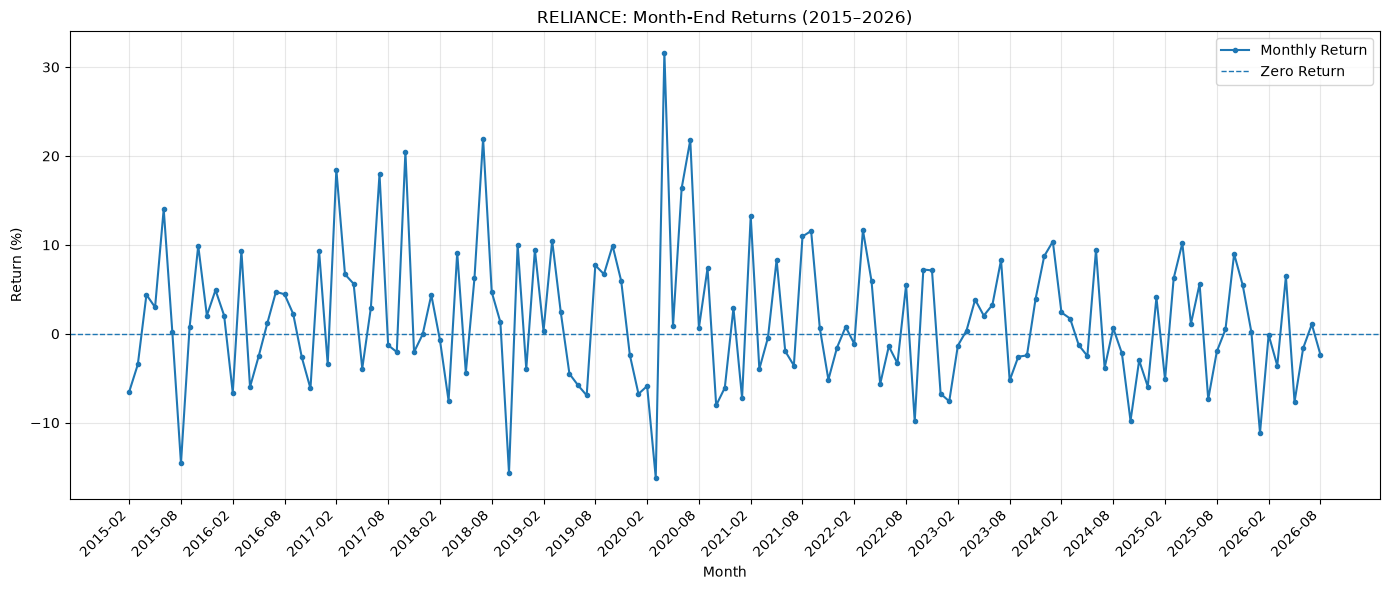

In [39]:
# Create a larger chart
plt.figure(figsize=(14, 6))

# Draw monthly returns
plt.plot(
    reliance_monthly["Month"].astype(str),
    reliance_monthly["MONTH_END_RETURN_PCT"],
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="Monthly Return"
)

# Add a zero-return reference line
plt.axhline(y=0, linestyle="--", linewidth=1, label="Zero Return")

# Add title and axis labels
plt.title("RELIANCE: Month-End Returns (2015–2026)")
plt.xlabel("Month")
plt.ylabel("Return (%)")

# Display one label every 6 months
tick_positions = range(0, len(reliance_monthly), 6)
plt.xticks(
    list(tick_positions),
    reliance_monthly["Month"].astype(str).iloc[list(tick_positions)],
    rotation=45,
    ha="right"
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Above 0%: The stock's closing price increased compared with the previous month-end.
# Below 0%: The stock's closing price decreased compared with the previous month-end.
# Large spikes: These indicate unusually large monthly price movements that may need investigation.
# Dashed horizontal line: This marks a 0% return.

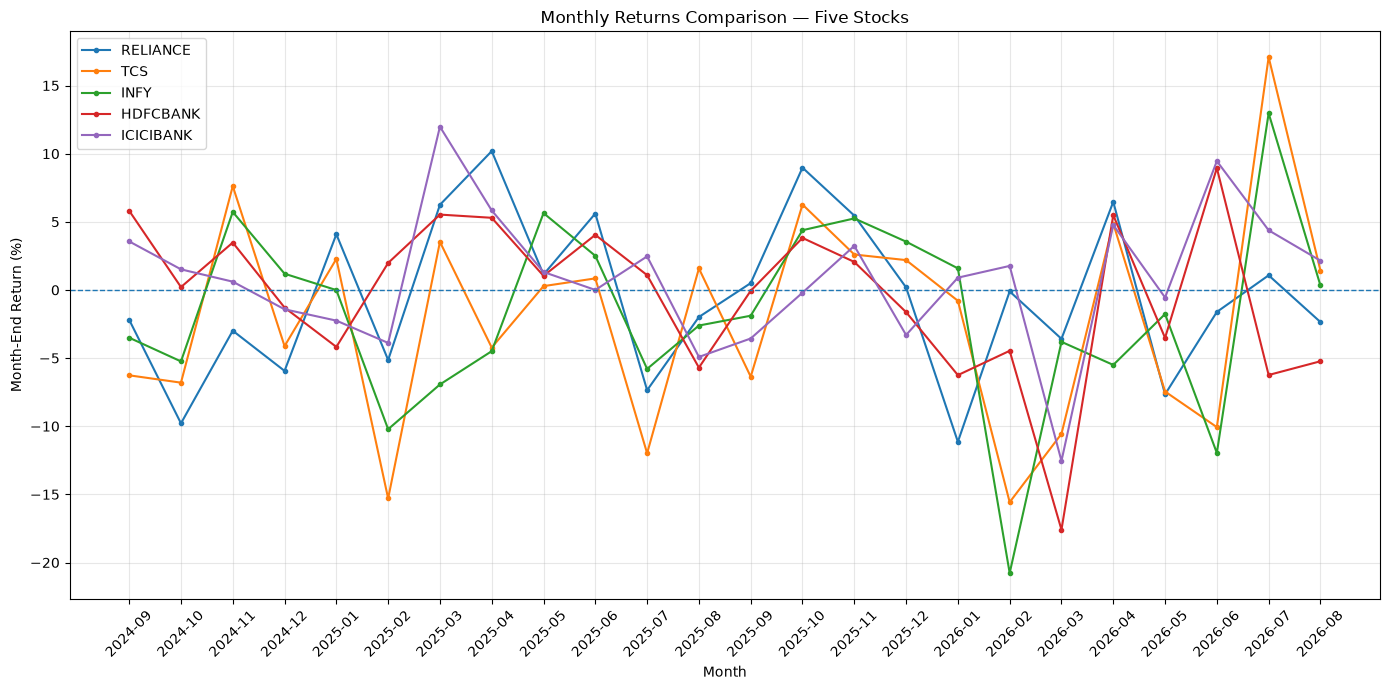

In [40]:
# Select five stocks for comparison
selected_stocks = [
    "RELIANCE",
    "TCS",
    "INFY",
    "HDFCBANK",
    "ICICIBANK"
]

# Keep the most recent 24 months in the monthly dataset
latest_month = monthly_prices["Month"].max()
start_month = latest_month - 23

comparison = monthly_prices[
    (monthly_prices["Symbol"].isin(selected_stocks))
    & (monthly_prices["Month"] >= start_month)
    & (monthly_prices["Month"] <= latest_month)
].copy()

# Create the comparison chart
plt.figure(figsize=(14, 7))

for symbol in selected_stocks:
    stock_data = comparison[comparison["Symbol"] == symbol]

    plt.plot(
        stock_data["Month"].astype(str),
        stock_data["MONTH_END_RETURN_PCT"],
        marker="o",
        markersize=3,
        label=symbol
    )

plt.axhline(y=0, linestyle="--", linewidth=1)
plt.title("Monthly Returns Comparison — Five Stocks")
plt.xlabel("Month")
plt.ylabel("Month-End Return (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
# Which of these fives stocks had the highest average monthly returns ,and which had the Greatest Variablility?

# Summarize monthly returns for the five selected stocks
performance_summary = (
    comparison.groupby("Symbol")
    .agg(
        Average_Monthly_Return=("MONTH_END_RETURN_PCT", "mean"),
        Median_Monthly_Return=("MONTH_END_RETURN_PCT", "median"),
        Monthly_Return_Std=("MONTH_END_RETURN_PCT", "std"),
        Best_Month=("MONTH_END_RETURN_PCT", "max"),
        Worst_Month=("MONTH_END_RETURN_PCT", "min"),
        Number_of_Months=("MONTH_END_RETURN_PCT", "count")
    )
    .round(2)
    .sort_values("Average_Monthly_Return", ascending=False)
)

display(performance_summary)

,Average_Monthly_Return,Median_Monthly_Return,Monthly_Return_Std,Best_Month,Worst_Month,Number_of_Months
Symbol,,,,,,
ICICIBANK,0.89,1.11,4.93,11.98,-12.55,24
HDFCBANK,-0.31,0.62,5.73,8.94,-17.60,24
RELIANCE,-0.50,-0.86,5.80,10.19,-11.14,24
INFY,-1.73,-1.83,6.95,12.96,-20.77,24
TCS,-2.04,-0.26,7.80,17.08,-15.57,24


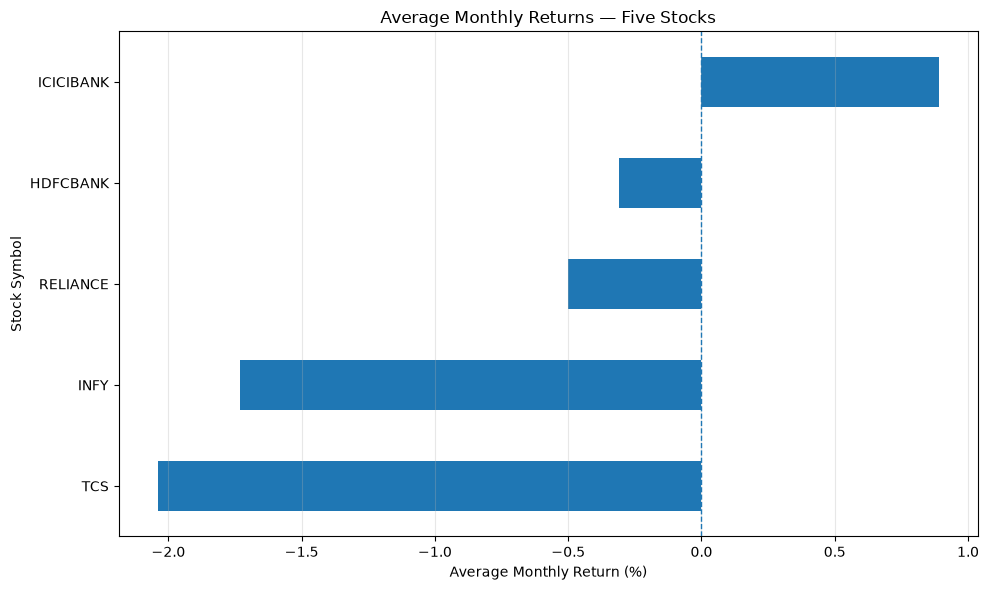

In [42]:
#  Create a Bar Chart of Average Monthly Returns.

plt.figure(figsize=(10, 6))

performance_summary["Average_Monthly_Return"].sort_values().plot(
    kind="barh"
)

plt.axvline(x=0, linestyle="--", linewidth=1)
plt.title("Average Monthly Returns — Five Stocks")
plt.xlabel("Average Monthly Return (%)")
plt.ylabel("Stock Symbol")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

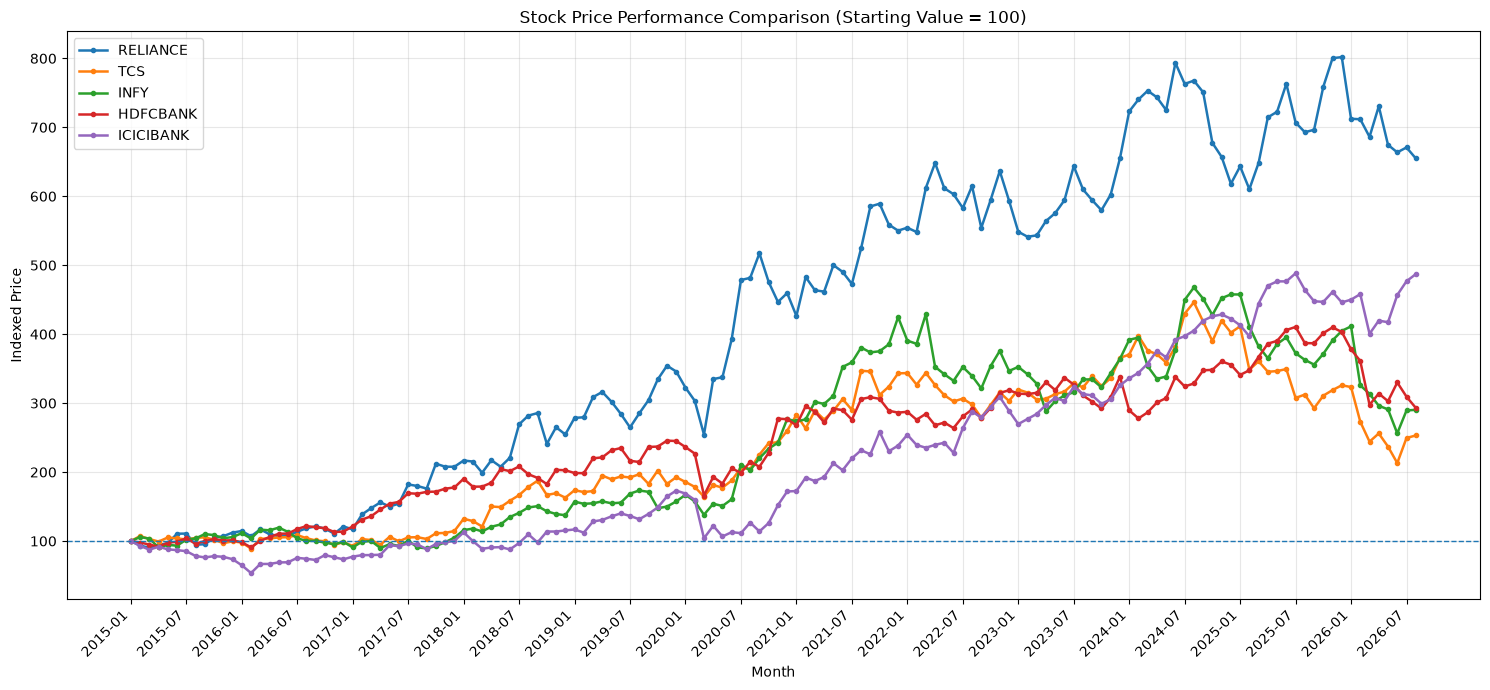

In [44]:
# Create a cleaner comparison chart
plt.figure(figsize=(15, 7))

for symbol in selected_stocks:

    stock_data = monthly_close_comparison[
        monthly_close_comparison["Symbol"] == symbol
    ].sort_values("Month")

    plt.plot(
        stock_data["Month"].astype(str),
        stock_data["PRICE_INDEX"],
        marker="o",
        markersize=3,
        linewidth=1.8,
        label=symbol
    )

# Show starting index reference
plt.axhline(y=100, linestyle="--", linewidth=1)

# Display one date label every six months
tick_positions = range(0, len(stock_data), 6)

plt.xticks(
    list(tick_positions),
    stock_data["Month"].astype(str).iloc[list(tick_positions)],
    rotation=45,
    ha="right"
)

plt.title("Stock Price Performance Comparison (Starting Value = 100)")
plt.xlabel("Month")
plt.ylabel("Indexed Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
# Create a Stock Perfromance Ranking Table.

# TO create an Exact Numerical Ranking instead of Estimating values from the chart.

# Get the first and latest recorded monthly closing prices
stock_ranking = (
    monthly_close_comparison
    .sort_values(["Symbol", "Month"])
    .groupby("Symbol")
    .agg(
        Starting_Close=("Last_Close", "first"),
        Latest_Close=("Last_Close", "last")
    )
)

# Calculate total price change percentage
stock_ranking["Total_Price_Change_PCT"] = (
    (stock_ranking["Latest_Close"] - stock_ranking["Starting_Close"])
    / stock_ranking["Starting_Close"]
) * 100

# Rank stocks by price change
stock_ranking["Rank"] = (
    stock_ranking["Total_Price_Change_PCT"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Display ranking
stock_ranking = stock_ranking.sort_values("Rank")

display(stock_ranking.round(2))

,Starting_Close,Latest_Close,Total_Price_Change_PCT,Rank
Symbol,,,,
RELIANCE,194.95,1277.0,555.04,1
ICICIBANK,298.52,1454.0,387.07,2
HDFCBANK,241.83,709.0,193.19,3
INFY,390.52,1133.8,190.33,4
TCS,948.02,2399.3,153.09,5


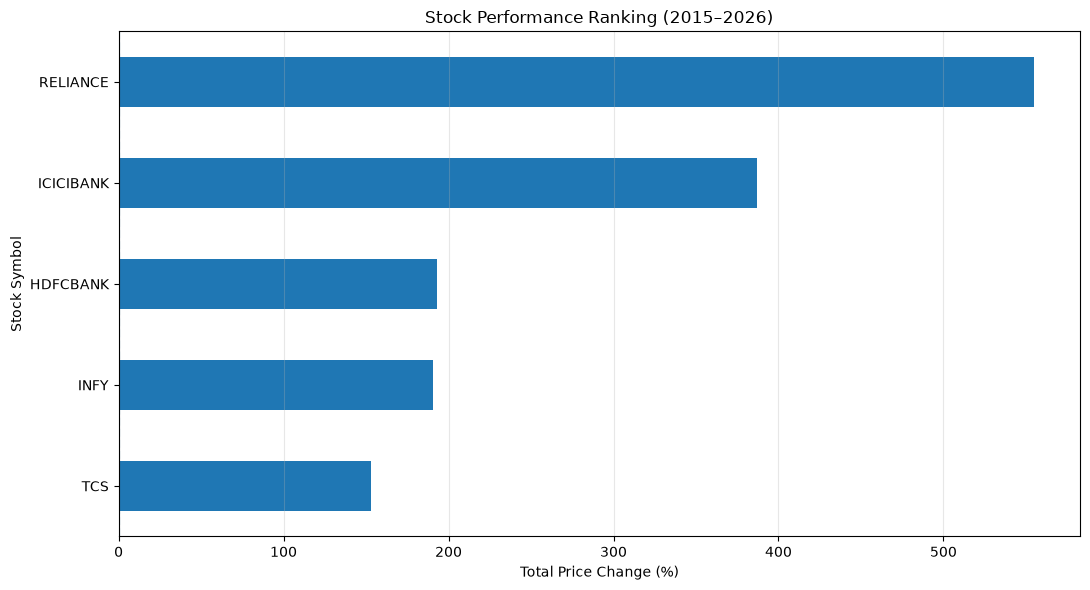

In [46]:
#  TO Create the Stock Ranking Bar Chart.

# Create stock performance ranking chart
plt.figure(figsize=(11, 6))

stock_ranking["Total_Price_Change_PCT"].sort_values().plot(
    kind="barh"
)

plt.title("Stock Performance Ranking (2015–2026)")
plt.xlabel("Total Price Change (%)")
plt.ylabel("Stock Symbol")

plt.axvline(x=0, linestyle="--")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
#  IT COMPARES THE TOTAL PERCENTAGE PRICE CHANGE OF FIVE STOCKS BETWEEN JANUARY 2015 AND AUGUST 2026.

In [47]:
# STOCK VOLATILITY AND RISK ANALYSIS..

# HOW MUCH A STOCK'S PRICE FLUCTUATE OVER TIME ?

# CALCULATE THE DAILY VOLATILITY ?

# Select the five stocks
selected_daily_returns = stocks[
    stocks["Symbol"].isin(selected_stocks)
].copy()

# Calculate daily volatility for each stock
daily_volatility = (
    selected_daily_returns
    .groupby("Symbol")["DAILY_RETURN_PCT"]
    .std()
    .sort_values(ascending=False)
)

# Display the results
print("Daily Stock Volatility (%)")

display(daily_volatility.round(3))

Daily Stock Volatility (%)


Symbol
ICICIBANK    1.890
RELIANCE     1.694
INFY         1.689
TCS          1.501
HDFCBANK     1.404
Name: DAILY_RETURN_PCT, dtype: float64

In [48]:
# CALCULATE ANNUALIZED VOLATILITY.

# Calculate daily volatility for each stock
daily_volatility = (
    selected_daily_returns
    .groupby("Symbol")["DAILY_RETURN_PCT"]
    .std()
)

# Convert daily volatility into annualized volatility
annual_volatility = daily_volatility * np.sqrt(252)

# Create a summary table
volatility_summary = pd.DataFrame({
    "Daily_Volatility_PCT": daily_volatility,
    "Annualized_Volatility_PCT": annual_volatility
})

# Sort from highest to lowest annualized volatility
volatility_summary = volatility_summary.sort_values(
    "Annualized_Volatility_PCT",
    ascending=False
)

display(volatility_summary.round(2))

,Daily_Volatility_PCT,Annualized_Volatility_PCT
Symbol,,
ICICIBANK,1.89,30.00
RELIANCE,1.69,26.89
INFY,1.69,26.80
TCS,1.50,23.83
HDFCBANK,1.40,22.29


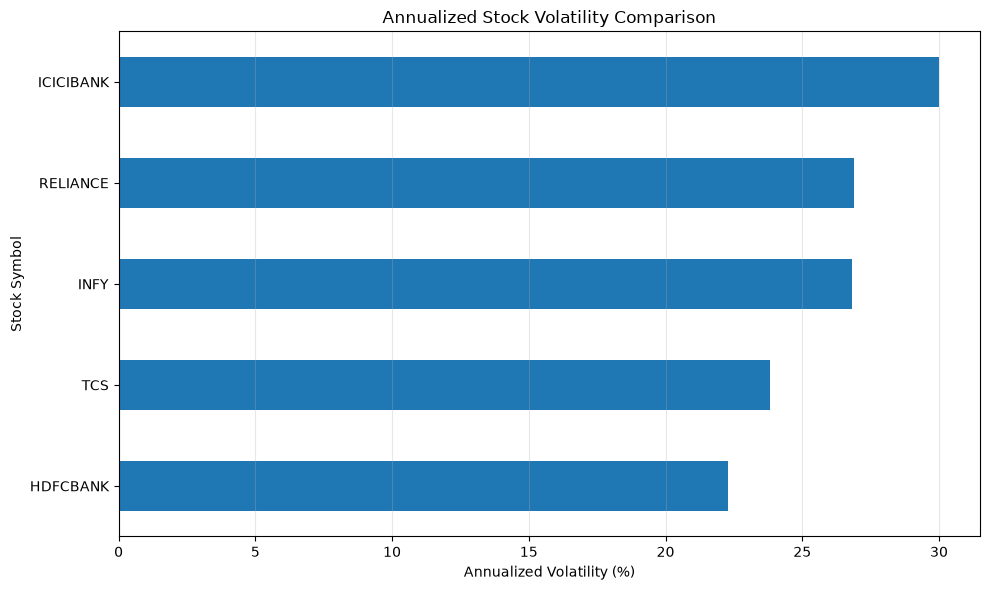

In [49]:
# VISUALIZE THE ANNUALIZED VOLATILITY COMPARISON.

# Create a volatility comparison chart
plt.figure(figsize=(10, 6))

volatility_summary["Annualized_Volatility_PCT"].sort_values().plot(
    kind="barh"
)

plt.title("Annualized Stock Volatility Comparison")
plt.xlabel("Annualized Volatility (%)")
plt.ylabel("Stock Symbol")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# A longer bar indicates higher historical annualized volatility.
# A shorter bar indicates lower historical annualized volatility.

In [50]:
# RISK VS RETURNS.

# CALCULATE THE RISK VS RETURN FOR YOUR FIVE STOCKS.

# Calculate average monthly return and monthly volatility
risk_return_summary = (
    comparison.groupby("Symbol")
    .agg(
        Average_Monthly_Return=("MONTH_END_RETURN_PCT", "mean"),
        Monthly_Volatility=("MONTH_END_RETURN_PCT", "std")
    )
    .reset_index()
)

# Display the results
display(
    risk_return_summary.sort_values(
        "Average_Monthly_Return",
        ascending=False
    ).round(2)
)

,Symbol,Average_Monthly_Return,Monthly_Volatility
1,ICICIBANK,0.89,4.93
0,HDFCBANK,-0.31,5.73
3,RELIANCE,-0.50,5.80
2,INFY,-1.73,6.95
4,TCS,-2.04,7.80


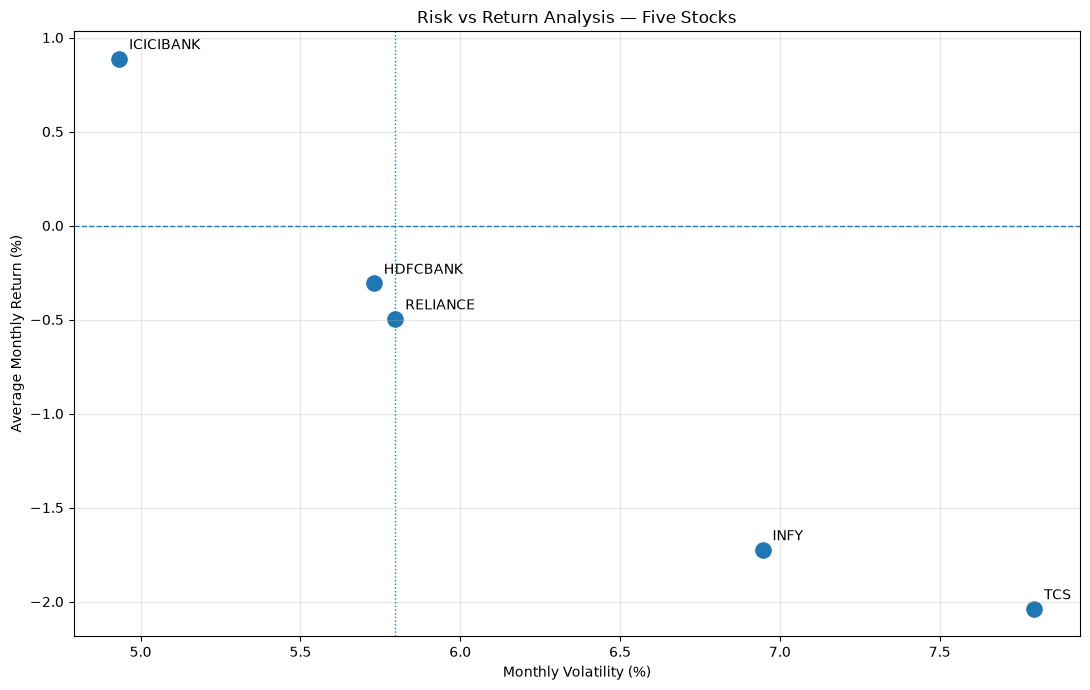

In [51]:
# CREATE THE RISK VS RETURNS SCOTTER PLOT.

# Create the risk vs return scatter plot
plt.figure(figsize=(11, 7))

plt.scatter(
    risk_return_summary["Monthly_Volatility"],
    risk_return_summary["Average_Monthly_Return"],
    s=120
)

# Add stock names beside each point
for _, row in risk_return_summary.iterrows():

    plt.annotate(
        row["Symbol"],
        (
            row["Monthly_Volatility"],
            row["Average_Monthly_Return"]
        ),
        xytext=(7, 7),
        textcoords="offset points"
    )

# Add reference lines
plt.axhline(y=0, linestyle="--", linewidth=1)
plt.axvline(
    x=risk_return_summary["Monthly_Volatility"].median(),
    linestyle=":",
    linewidth=1
)

plt.title("Risk vs Return Analysis — Five Stocks")
plt.xlabel("Monthly Volatility (%)")
plt.ylabel("Average Monthly Return (%)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [52]:
# TO CALCULATE THE MONTHLY SHARPE RATIO FOR YOUR FIVE STOCKS.

# Assume zero monthly risk-free rate for this learning exercise
monthly_risk_free_rate = 0

# Calculate monthly Sharpe Ratio
risk_return_summary["Monthly_Sharpe_Ratio"] = (
    risk_return_summary["Average_Monthly_Return"]
    - monthly_risk_free_rate
) / risk_return_summary["Monthly_Volatility"]

# Display the results
display(
    risk_return_summary.sort_values(
        "Monthly_Sharpe_Ratio",
        ascending=False
    ).round(3)
)

,Symbol,Average_Monthly_Return,Monthly_Volatility,Monthly_Sharpe_Ratio
1,ICICIBANK,0.887,4.934,0.180
0,HDFCBANK,-0.308,5.730,-0.054
3,RELIANCE,-0.497,5.797,-0.086
2,INFY,-1.725,6.946,-0.248
4,TCS,-2.039,7.796,-0.262


In [53]:
# Annualized Sharpe Ratios.

# Calculate annualized Sharpe Ratio
risk_return_summary["Annualized_Sharpe_Ratio"] = (
    risk_return_summary["Monthly_Sharpe_Ratio"]
    * np.sqrt(12)
)

# Sort stocks by annualized Sharpe Ratio
sharpe_ranking = risk_return_summary.sort_values(
    "Annualized_Sharpe_Ratio",
    ascending=False
)

# Display results
display(
    sharpe_ranking[
        [
            "Average_Monthly_Return",
            "Monthly_Volatility",
            "Monthly_Sharpe_Ratio",
            "Annualized_Sharpe_Ratio"
        ]
    ].round(3)
)

,Average_Monthly_Return,Monthly_Volatility,Monthly_Sharpe_Ratio,Annualized_Sharpe_Ratio
1,0.887,4.934,0.180,0.623
0,-0.308,5.730,-0.054,-0.186
3,-0.497,5.797,-0.086,-0.297
2,-1.725,6.946,-0.248,-0.860
4,-2.039,7.796,-0.262,-0.906


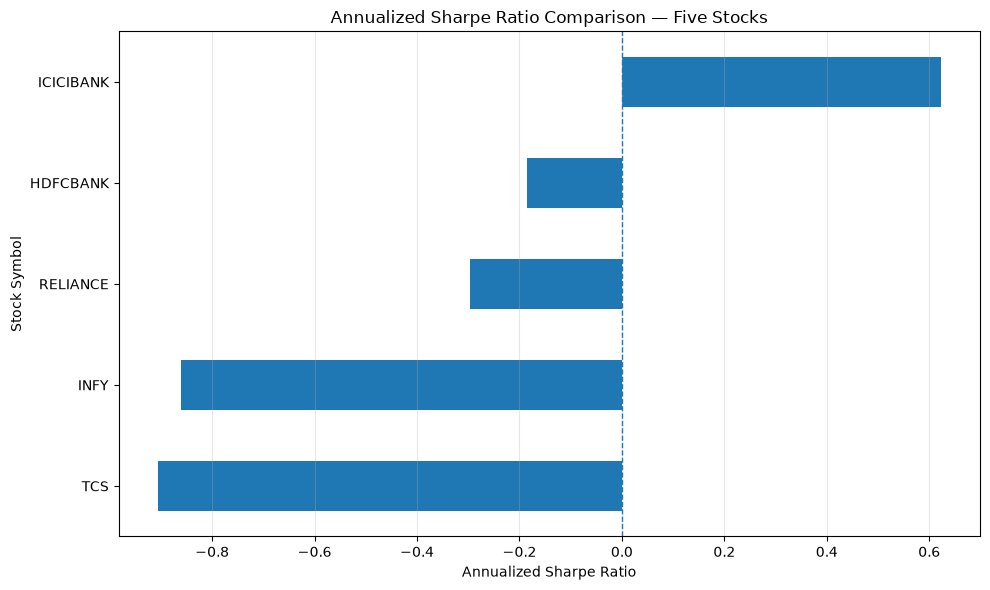

In [55]:
# Create the Annualized Sharpe Ratio Ranking.

# Visualize which stock had the highest and lowest risk -adjusted Performance.

# Use stock symbols as the chart index
sharpe_chart_data = (
    sharpe_ranking
    .set_index("Symbol")["Annualized_Sharpe_Ratio"]
    .sort_values()
)

# Create the corrected chart
plt.figure(figsize=(10, 6))

sharpe_chart_data.plot(kind="barh")

plt.axvline(x=0, linestyle="--", linewidth=1)

plt.title("Annualized Sharpe Ratio Comparison — Five Stocks")
plt.xlabel("Annualized Sharpe Ratio")
plt.ylabel("Stock Symbol")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Bars extending to the right indicate positive Sharpe Ratios.
# Bars extending to the left indicate negative Sharpe Ratios.
# ICICIBANK should have the longest positive bar.
# TCS should have the most negative bar.


In [56]:
# PORTFOLIO ANALYSIS.

# CREATE AN EQUALLY WEIGHTED PORTFOLIO.

# Convert monthly stock returns into a comparison table
monthly_stock_returns = comparison.pivot(
    index="Month",
    columns="Symbol",
    values="MONTH_END_RETURN_PCT"
)

# Check missing monthly returns
print("Missing monthly returns:")
print(monthly_stock_returns.isnull().sum())

# Keep only months where all five stocks have returns
complete_months = monthly_stock_returns.dropna()

# Calculate equally weighted portfolio return
portfolio_returns = complete_months.mean(axis=1)

# Display portfolio returns
print("\nNumber of complete months:", len(portfolio_returns))

display(portfolio_returns.head(10))

Missing monthly returns:
Symbol
HDFCBANK     0
ICICIBANK    0
INFY         0
RELIANCE     0
TCS          0
dtype: int64

Number of complete months: 24


Month
2024-09   -0.516177
2024-10   -4.022151
2024-11    2.887559
2024-12   -2.316047
2025-01   -0.015730
2025-02   -6.512479
2025-03    4.070420
2025-04    2.519213
2025-05    1.880506
2025-06    2.600309
Freq: M, dtype: float64

In [57]:
# CALUCULATE THE PORTFOLIO PERFROMANCE.

# Total Cummulative Portfolio Return.
# Average Monthly Portfolio Return.
# Annualized Portfolio Volatility.
# Annualized Portfolio Return.


# Calculate cumulative portfolio growth
portfolio_growth = (1 + portfolio_returns / 100).cumprod()

# Calculate total portfolio return
total_portfolio_return = (portfolio_growth.iloc[-1] - 1) * 100

# Calculate average monthly return
average_monthly_return = portfolio_returns.mean()

# Calculate annualized volatility
annualized_portfolio_volatility = (
    portfolio_returns.std() * np.sqrt(12)
)

# Calculate annualized compounded return
number_of_months = len(portfolio_returns)

annualized_portfolio_return = (
    portfolio_growth.iloc[-1] ** (12 / number_of_months) - 1
) * 100

# Display portfolio performance
print("PORTFOLIO PERFORMANCE SUMMARY")
print("--------------------------------")
print("Total Portfolio Return:", round(total_portfolio_return, 2), "%")
print("Average Monthly Return:", round(average_monthly_return, 2), "%")
print("Annualized Portfolio Return:", round(annualized_portfolio_return, 2), "%")
print("Annualized Portfolio Volatility:", round(annualized_portfolio_volatility, 2), "%")


PORTFOLIO PERFORMANCE SUMMARY
--------------------------------
Total Portfolio Return: -17.9 %
Average Monthly Return: -0.74 %
Annualized Portfolio Return: -9.39 %
Annualized Portfolio Volatility: 14.21 %


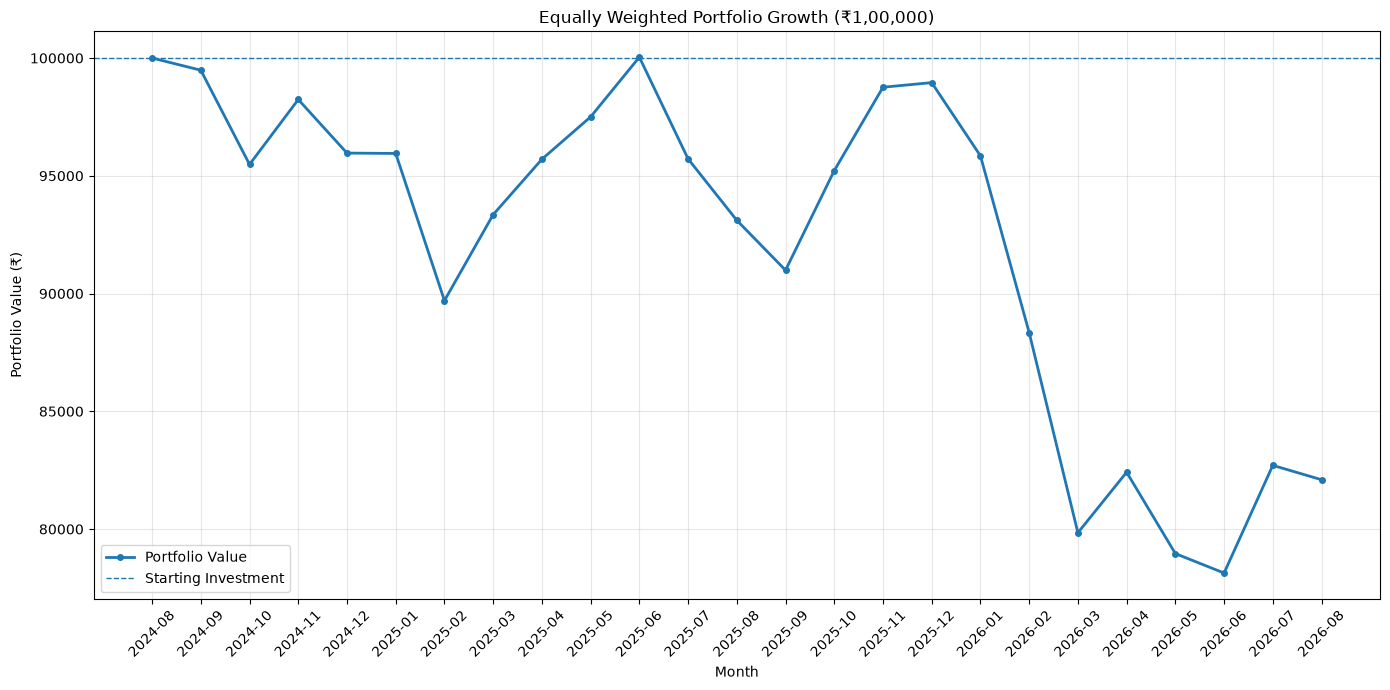

In [58]:
#  Visualize the Portfolio Value Changed over the 24 Months.

# start with ₹1,00,000 and apply each month's portfolio return.


# Assume an initial portfolio investment of ₹1,00,000
initial_investment = 100000

# Calculate portfolio value over time
portfolio_value = initial_investment * portfolio_growth

# Add the starting value to the series
portfolio_chart = pd.concat([
    pd.Series(
        [initial_investment],
        index=[portfolio_returns.index[0] - 1]
    ),
    portfolio_value
])

# Create the portfolio growth chart
plt.figure(figsize=(14, 7))

plt.plot(
    portfolio_chart.index.astype(str),
    portfolio_chart.values,
    marker="o",
    markersize=4,
    linewidth=2,
    label="Portfolio Value"
)

plt.axhline(
    y=initial_investment,
    linestyle="--",
    linewidth=1,
    label="Starting Investment"
)

plt.title("Equally Weighted Portfolio Growth (₹1,00,000)")
plt.xlabel("Month")
plt.ylabel("Portfolio Value (₹)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [59]:
# Calculate the Unequal-Weighted Portfolio.

# Define unequal portfolio weights
portfolio_weights = pd.Series({
    "RELIANCE": 0.25,
    "TCS": 0.20,
    "INFY": 0.20,
    "HDFCBANK": 0.20,
    "ICICIBANK": 0.15
})

# Calculate monthly unequal-weighted portfolio returns
unequal_portfolio_returns = (
    complete_months.mul(portfolio_weights, axis="columns")
    .sum(axis=1)
)

# Calculate cumulative portfolio growth
unequal_portfolio_growth = (
    1 + unequal_portfolio_returns / 100
).cumprod()

# Calculate portfolio value starting with ₹1,00,000
unequal_portfolio_value = (
    100000 * unequal_portfolio_growth
)

# Display first 10 monthly returns
print("Unequally Weighted Portfolio Returns:")
display(unequal_portfolio_returns.head(10))

# Display ending portfolio value
print(
    "Ending Portfolio Value: ₹",
    round(unequal_portfolio_value.iloc[-1], 2)
)

Unequally Weighted Portfolio Returns:


Month
2024-09   -0.803807
2024-10   -4.587151
2024-11    2.707603
2024-12   -2.542066
2025-01    0.301066
2025-02   -6.575011
2025-03    3.783899
2025-04    2.736932
2025-05    1.871218
2025-06    2.880765
Freq: M, dtype: float64

Ending Portfolio Value: ₹ 80680.44


In [60]:
# Calculate the Performance measurement for both Portfolios.

# Calculate performance metrics for both portfolios

portfolio_comparison = pd.DataFrame({
    "Equal_Weighted": portfolio_returns,
    "Unequal_Weighted": unequal_portfolio_returns
})

# Calculate total compounded returns
total_returns = (
    (1 + portfolio_comparison / 100).prod() - 1
) * 100

# Calculate average monthly returns
average_returns = portfolio_comparison.mean()

# Calculate annualized volatility
annualized_volatility = (
    portfolio_comparison.std() * np.sqrt(12)
)

# Calculate annualized compounded returns
months = len(portfolio_comparison)

annualized_returns = (
    (1 + portfolio_comparison / 100).prod()
    ** (12 / months) - 1
) * 100

# Create comparison summary
portfolio_summary = pd.DataFrame({
    "Total_Return_PCT": total_returns,
    "Average_Monthly_Return_PCT": average_returns,
    "Annualized_Return_PCT": annualized_returns,
    "Annualized_Volatility_PCT": annualized_volatility
})

display(portfolio_summary.round(2))

,Total_Return_PCT,Average_Monthly_Return_PCT,Annualized_Return_PCT,Annualized_Volatility_PCT
Equal_Weighted,-17.90,-0.74,-9.39,14.21
Unequal_Weighted,-19.32,-0.81,-10.18,14.45


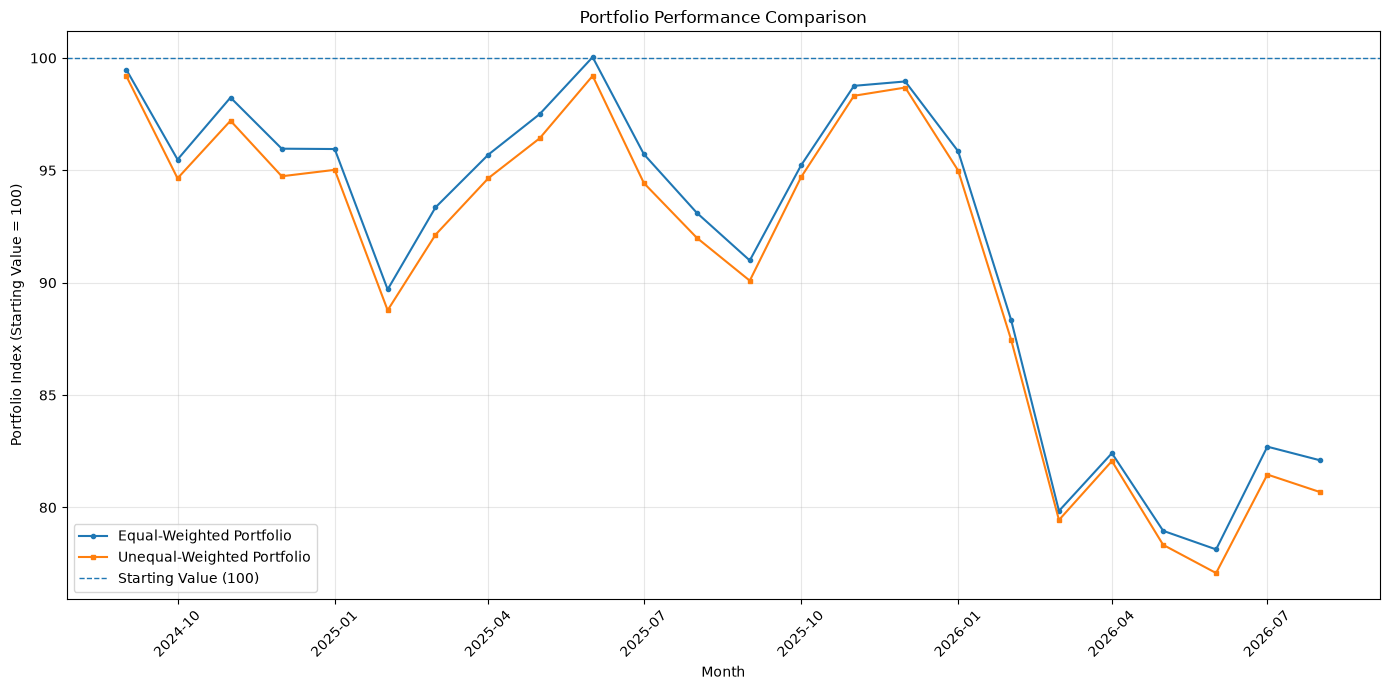

In [62]:
# Visualize the both Portfolio together.

# Create portfolio growth comparison

# Convert monthly Period indexes into datetime indexes
equal_dates = portfolio_growth.index.to_timestamp()

unequal_dates = unequal_portfolio_growth.index.to_timestamp()

# Create portfolio growth comparison
plt.figure(figsize=(14, 7))

plt.plot(
    equal_dates,
    portfolio_growth.values * 100,
    marker="o",
    markersize=3,
    label="Equal-Weighted Portfolio"
)

plt.plot(
    unequal_dates,
    unequal_portfolio_growth.values * 100,
    marker="s",
    markersize=3,
    label="Unequal-Weighted Portfolio"
)

# Starting investment reference
plt.axhline(
    y=100,
    linestyle="--",
    linewidth=1,
    label="Starting Value (100)"
)

plt.title("Portfolio Performance Comparison")
plt.xlabel("Month")
plt.ylabel("Portfolio Index (Starting Value = 100)")

plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [63]:
# Diversification and Correlation.

# Calculate the Correlation Matrix.

# Calculate correlation between the five stocks
correlation_matrix = complete_months.corr()

# Display correlation results
display(correlation_matrix.round(3))

Symbol,HDFCBANK,ICICIBANK,INFY,RELIANCE,TCS
Symbol,,,,,
HDFCBANK,1.000,0.700,-0.126,0.392,0.052
ICICIBANK,0.700,1.000,-0.130,0.305,0.218
INFY,-0.126,-0.130,1.000,0.132,0.790
RELIANCE,0.392,0.305,0.132,1.000,0.433
TCS,0.052,0.218,0.790,0.433,1.000


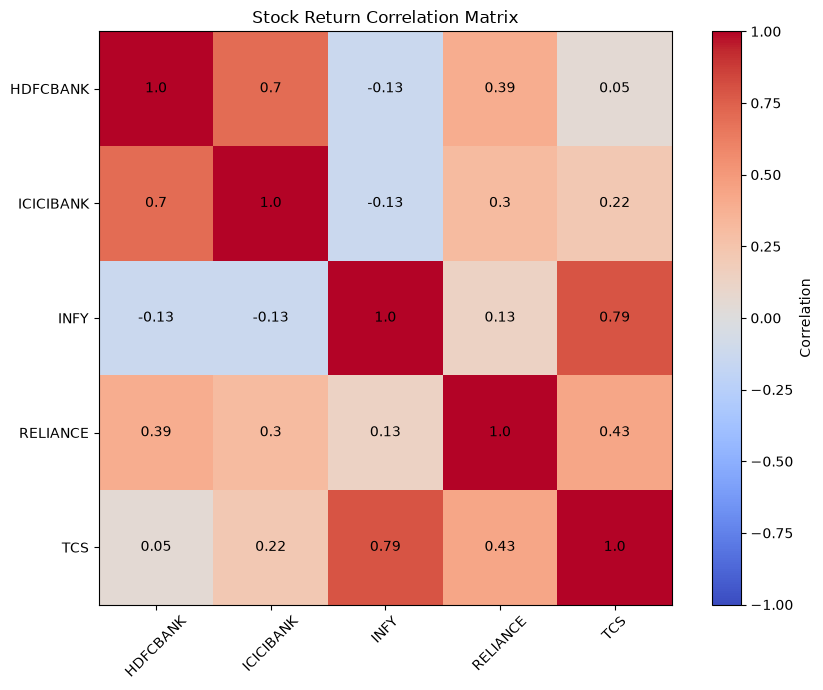

In [64]:
plt.figure(figsize=(9, 7))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)

# Display correlation values inside the chart
for i in range(len(correlation_matrix.index)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j,
            i,
            round(correlation_matrix.iloc[i, j], 2),
            ha="center",
            va="center"
        )

plt.title("Stock Return Correlation Matrix")
plt.tight_layout()
plt.show()

In [66]:
# Find the Most/Highest and Least/Lowest Correlation Stocks Pairs.


# Remove index and column names to avoid naming conflicts
correlation_matrix.index.name = None
correlation_matrix.columns.name = None

# Extract only the upper triangle
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

# Convert the matrix into stock pairs
correlation_pairs = (
    upper_triangle
    .rename_axis(index="Stock_1", columns="Stock_2")
    .stack()
    .reset_index()
)

# Rename columns
correlation_pairs.columns = [
    "Stock_1",
    "Stock_2",
    "Correlation"
]

# Sort correlations
highest_correlations = correlation_pairs.sort_values(
    "Correlation",
    ascending=False
)

# Display highest correlated pairs
print("TOP 5 MOST CORRELATED STOCK PAIRS")

display(highest_correlations.head(5).round(3))

# Display lowest correlated pairs
print("TOP 5 LEAST CORRELATED STOCK PAIRS")

display(highest_correlations.tail(5).round(3))

TOP 5 MOST CORRELATED STOCK PAIRS


,Stock_1,Stock_2,Correlation
14,INFY,TCS,0.790
1,HDFCBANK,ICICIBANK,0.700
19,RELIANCE,TCS,0.433
3,HDFCBANK,RELIANCE,0.392
8,ICICIBANK,RELIANCE,0.305


TOP 5 LEAST CORRELATED STOCK PAIRS


,Stock_1,Stock_2,Correlation
20,TCS,HDFCBANK,NaN
21,TCS,ICICIBANK,NaN
22,TCS,INFY,NaN
23,TCS,RELIANCE,NaN
24,TCS,TCS,NaN


In [67]:
# REMOVE THE EMPTY CELLS BEFORE RANKING.

# Extract the upper triangle, excluding the diagonal
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

# Convert into stock pairs and remove missing values
correlation_pairs = (
    upper_triangle
    .stack()
    .dropna()
    .rename_axis(index=["Stock_1", "Stock_2"])
    .reset_index(name="Correlation")
)

# Five highest correlations
print("TOP 5 MOST CORRELATED STOCK PAIRS")

display(
    correlation_pairs.nlargest(
        5, "Correlation"
    ).round(3)
)

# Five lowest correlations
print("TOP 5 LEAST CORRELATED STOCK PAIRS")

display(
    correlation_pairs.nsmallest(
        5, "Correlation"
    ).round(3)
)

TOP 5 MOST CORRELATED STOCK PAIRS


,Stock_1,Stock_2,Correlation
8,INFY,TCS,0.790
0,HDFCBANK,ICICIBANK,0.700
9,RELIANCE,TCS,0.433
2,HDFCBANK,RELIANCE,0.392
5,ICICIBANK,RELIANCE,0.305


TOP 5 LEAST CORRELATED STOCK PAIRS


,Stock_1,Stock_2,Correlation
4,ICICIBANK,INFY,-0.130
1,HDFCBANK,INFY,-0.126
3,HDFCBANK,TCS,0.052
7,INFY,RELIANCE,0.132
6,ICICIBANK,TCS,0.218


In [68]:
# Claculate the Portfolio Volatility.

# Create a comparison of three portfolios

diversification_returns = pd.DataFrame({
    "Low_Correlation_Portfolio":
        complete_months[["ICICIBANK", "INFY"]].mean(axis=1),

    "High_Correlation_Portfolio":
        complete_months[["INFY", "TCS"]].mean(axis=1),

    "Five_Stock_Portfolio":
        portfolio_returns
})

# Calculate monthly volatility
monthly_volatility = diversification_returns.std()

# Calculate annualized volatility
annualized_volatility = monthly_volatility * np.sqrt(12)

# Create comparison table
diversification_summary = pd.DataFrame({
    "Monthly_Volatility": monthly_volatility,
    "Annualized_Volatility": annualized_volatility
})

print("DIVERSIFICATION BENEFIT ANALYSIS")

display(diversification_summary.round(3))

DIVERSIFICATION BENEFIT ANALYSIS


,Monthly_Volatility,Annualized_Volatility
Low_Correlation_Portfolio,3.990,13.820
High_Correlation_Portfolio,6.975,24.161
Five_Stock_Portfolio,4.102,14.210


In [69]:
# Calculate the Diversification Benefit Percentage.

# Calculatet how much Volatility was reduced by Combining Two stocks.

# To compare the Portfolio Volatility with the average Volatility of its two individual stocks.

# Calculate individual stock monthly volatility
individual_volatility = complete_months.std()

# Calculate average individual volatility for each pair
low_pair_average = individual_volatility[
    ["ICICIBANK", "INFY"]
].mean()

high_pair_average = individual_volatility[
    ["INFY", "TCS"]
].mean()

# Calculate diversification benefit
low_diversification_benefit = (
    (low_pair_average - monthly_volatility["Low_Correlation_Portfolio"])
    / low_pair_average
) * 100

high_diversification_benefit = (
    (high_pair_average - monthly_volatility["High_Correlation_Portfolio"])
    / high_pair_average
) * 100

# Display results
print("LOW-CORRELATION PORTFOLIO BENEFIT:",
      round(low_diversification_benefit, 2), "%")

print("HIGH-CORRELATION PORTFOLIO BENEFIT:",
      round(high_diversification_benefit, 2), "%")

LOW-CORRELATION PORTFOLIO BENEFIT: 32.84 %
HIGH-CORRELATION PORTFOLIO BENEFIT: 5.38 %


In [71]:
# PORTFOLIO DRAWDOWN ANALYSIS.

# Calculate the Portfolio Drawdown.

# Include the original starting portfolio value (index = 1.0)
equal_growth_with_start = pd.concat([
    pd.Series(
        [1.0],
        index=pd.PeriodIndex(
            [portfolio_returns.index[0] - 1], freq="M"
        )
    ),
    (1 + portfolio_returns / 100).cumprod()
])

unequal_growth_with_start = pd.concat([
    pd.Series(
        [1.0],
        index=pd.PeriodIndex(
            [unequal_portfolio_returns.index[0] - 1], freq="M"
        )
    ),
    (1 + unequal_portfolio_returns / 100).cumprod()
])

# Calculate previous highest values
equal_peak = equal_growth_with_start.cummax()
unequal_peak = unequal_growth_with_start.cummax()

# Calculate drawdowns
equal_drawdown = (equal_growth_with_start / equal_peak - 1) * 100
unequal_drawdown = (unequal_growth_with_start / unequal_peak - 1) * 100

# Calculate maximum drawdown
equal_max_drawdown = equal_drawdown.min()
unequal_max_drawdown = unequal_drawdown.min()

print("EQUAL-WEIGHTED MAXIMUM DRAWDOWN:",
      round(equal_max_drawdown, 2), "%")

print("UNEQUAL-WEIGHTED MAXIMUM DRAWDOWN:",
      round(unequal_max_drawdown, 2), "%")

EQUAL-WEIGHTED MAXIMUM DRAWDOWN: -21.9 %
UNEQUAL-WEIGHTED MAXIMUM DRAWDOWN: -22.92 %


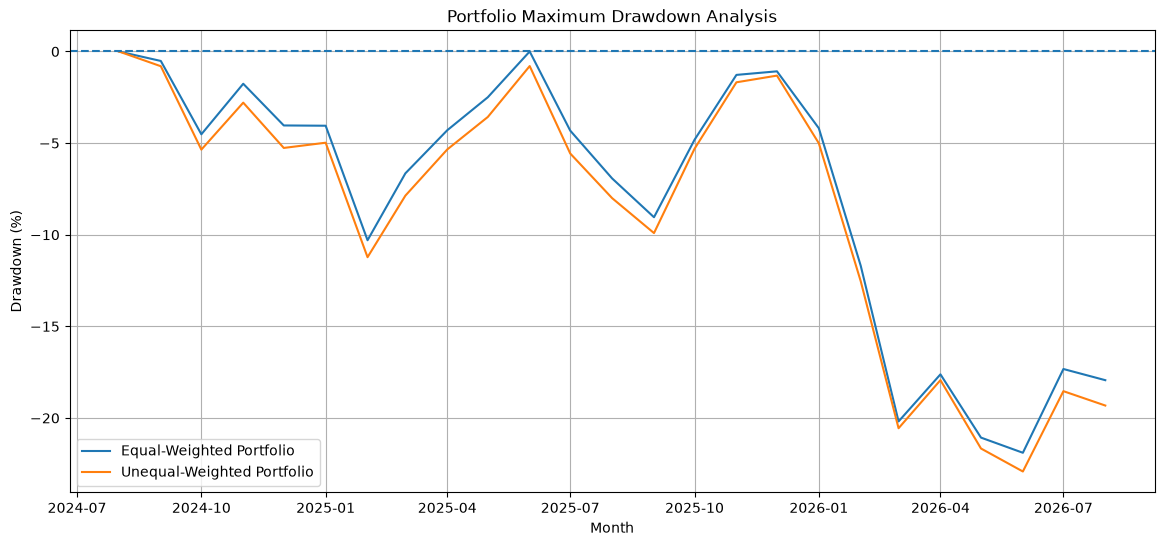

In [72]:
# Create the Portfolio Drawdown Chart.

# Visualize how both Portfolios moved below their Previous Peaks.

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    equal_drawdown.index.to_timestamp(),
    equal_drawdown,
    label="Equal-Weighted Portfolio"
)

plt.plot(
    unequal_drawdown.index.to_timestamp(),
    unequal_drawdown,
    label="Unequal-Weighted Portfolio"
)

plt.axhline(y=0, linestyle="--")

plt.title("Portfolio Maximum Drawdown Analysis")
plt.xlabel("Month")
plt.ylabel("Drawdown (%)")

plt.legend()
plt.grid(True)
plt.show()

In [74]:
# Build your Portfolio Comparison Table.

# the Portfolio Results Together in one table.

portfolio_comparison = pd.DataFrame({
    "Metric": [
        "Total Return (%)",
        "Average Monthly Return (%)",
        "Annualized Return (%)",
        "Annualized Volatility (%)",
        "Maximum Drawdown (%)"
    ],

    "Equal Weighted": [
        ( (1 + portfolio_returns / 100).prod() - 1) * 100,
        portfolio_returns.mean(),
        ((1 + portfolio_returns / 100).prod()
         ** (12 / len(portfolio_returns)) - 1) * 100,
        portfolio_returns.std() * (12 ** 0.5),
        equal_drawdown.min()
    ],

    "Unequal Weighted": [
        ((1 + unequal_portfolio_returns / 100).prod() - 1) * 100,
        unequal_portfolio_returns.mean(),
        ((1 + unequal_portfolio_returns / 100).prod()
         ** (12 / len(unequal_portfolio_returns)) - 1) * 100,
        unequal_portfolio_returns.std() * (12 ** 0.5),
        unequal_drawdown.min()
    ]
})

print(portfolio_comparison.round(2))

                       Metric  Equal Weighted  Unequal Weighted
0            Total Return (%)          -17.90            -19.32
1  Average Monthly Return (%)           -0.74             -0.81
2       Annualized Return (%)           -9.39            -10.18
3   Annualized Volatility (%)           14.21             14.45
4        Maximum Drawdown (%)          -21.90            -22.92


In [75]:
# Export your Analysis Tables.

# Export portfolio comparison
portfolio_comparison.to_csv(
    "portfolio_comparison.csv",
    index=False
)

# Export monthly portfolio returns
portfolio_returns.to_csv(
    "equal_weighted_monthly_returns.csv"
)

unequal_portfolio_returns.to_csv(
    "unequal_weighted_monthly_returns.csv"
)

# Export correlation matrix
correlation_matrix.to_csv(
    "stock_correlation_matrix.csv"
)

# Export risk-return summary
risk_return_summary.to_csv(
    "risk_return_summary.csv",
    index=False
)

print("All analysis files exported successfully!")

All analysis files exported successfully!


In [3]:
# Locate Your Exported Files.

import os

print("Current folder:")
print(os.getcwd())

print("\nExported CSV files:")

for file in os.listdir():
    if file.endswith(".csv"):
        print(file)

Current folder:
C:\Users\vinaya kumar

Exported CSV files:
equal_weighted_monthly_returns.csv
portfolio_comparison.csv
risk_return_summary.csv
stock_correlation_matrix.csv
unequal_weighted_monthly_returns.csv
